# Linear Discriminant Analysis, visually

One simulated dataset connects the geometry, Fisher's criterion, whitening, and optimization.

The next cell defines plotting helpers. **Run it, but you do not need to read it.** Later code cells focus on the mathematical steps.

In [1]:
# Run this cell once. It imports libraries and defines plotting helpers only.
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh


def scatter_classes(ax, X0, X1, alpha=0.5):
    ax.scatter(X0[:, 0], X0[:, 1], alpha=alpha, label="class 0")
    ax.scatter(X1[:, 0], X1[:, 1], alpha=alpha, label="class 1")
    ax.set(xlabel="$x_1$", ylabel="$x_2$")


def show_simulated_data(X0, X1, mu0, mu1):
    fig, ax = plt.subplots(figsize=(7, 6))
    scatter_classes(ax, X0, X1, alpha=0.6)
    ax.scatter([mu0[0], mu1[0]], [mu0[1], mu1[1]],
               marker="*", s=200, color="black", label="true means")
    ax.plot([mu0[0], mu1[0]], [mu0[1], mu1[1]], "k--", label="line between means")
    ax.set_title("Two simulated point clouds")
    ax.set_aspect("equal", adjustable="box")
    ax.legend()
    plt.show()


def show_within_class_scatter(X0, X1, m0, m1):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    scatter_classes(axes[0], X0, X1, alpha=0.25)
    for X, mean, color in [(X0, m0, "#1f77b4"), (X1, m1, "#ff7f0e")]:
        axes[0].scatter(*mean, marker="*", s=200, color=color, edgecolor="black")
        for point in X[::25]:
            axes[0].annotate("", xy=point, xytext=mean,
                             arrowprops={"arrowstyle": "->", "color": color, "alpha": 0.5})
    axes[0].set(xlim=(-4, 4), ylim=(-3, 4),
                title="Deviations from each class mean")
    axes[0].set_aspect("equal", adjustable="box")

    scatter_classes(axes[1], X0 - m0, X1 - m1, alpha=0.55)
    axes[1].axhline(0, color="gray", lw=0.7)
    axes[1].axvline(0, color="gray", lw=0.7)
    axes[1].scatter(0, 0, marker="*", s=200, color="black")
    axes[1].set(xlim=(-4, 4), ylim=(-4, 4),
                title="Centered clouds: variance and tilt remain")
    axes[1].set_aspect("equal", adjustable="box")
    fig.tight_layout()
    plt.show()


def show_projection(X0, X1, c, v, point, projection, P0, P1):
    fig, ax = plt.subplots(figsize=(8, 7))
    scatter_classes(ax, X0, X1, alpha=0.15)
    ax.axhline(0, color="gray", lw=0.7)
    ax.axvline(0, color="gray", lw=0.7)
    line = c + np.linspace(-4, 4, 2)[:, None] * v
    ax.plot(line[:, 0], line[:, 1], "k-", lw=1.5)
    ax.annotate("", xy=point, xytext=c,
                arrowprops={"arrowstyle": "->", "color": "#d62728", "lw": 2.5})
    ax.annotate("", xy=projection, xytext=c,
                arrowprops={"arrowstyle": "->", "color": "#2ca02c", "lw": 3})
    ax.plot([point[0], projection[0]], [point[1], projection[1]], "k:")
    ax.scatter(*c, marker="*", s=260, color="black", zorder=6)
    ax.scatter(*point, color="#d62728", s=110, zorder=6)
    ax.scatter(*projection, marker="X", color="gold", edgecolor="black", s=180, zorder=6)
    ax.annotate("reference c", xy=c, xytext=(-65, 30), textcoords="offset points",
                arrowprops={"arrowstyle": "->"})
    ax.annotate("original point x", xy=point, xytext=(10, 10), textcoords="offset points")
    ax.annotate("projected point p", xy=projection, xytext=(15, 25),
                textcoords="offset points", arrowprops={"arrowstyle": "->"})
    ax.text(0.65, 1.65, "$x-c$", color="#d62728", fontsize=14)
    ax.text(1.25, 0.2, "$p-c$", color="#2ca02c", fontsize=14)
    ax.set(xlim=(-4, 4), ylim=(-3, 4),
           title="Projection keeps the part of x - c along the line")
    ax.set_aspect("equal", adjustable="box")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    for ax in axes:
        ax.plot(line[:, 0], line[:, 1], "k-", lw=1.2)
        ax.scatter(*c, marker="*", s=220, color="black")
        ax.set(xlim=(-4, 4), ylim=(-3, 4), xlabel="$x_1$", ylabel="$x_2$")
        ax.set_aspect("equal", adjustable="box")
    scatter_classes(axes[0], X0, X1, alpha=0.5)
    axes[0].set_title("Before projection")
    scatter_classes(axes[1], P0, P1, alpha=0.7)
    axes[1].set_title("After projection: every point is on the line")
    fig.tight_layout()
    plt.show()


def show_projected_mean_variance(X0, X1, c, v, t0, t1, m0, m1):
    X0_relative = X0 - c
    X1_relative = X1 - c
    m0_relative = m0 - c
    m1_relative = m1 - c
    projected_m0 = t0.mean() * v
    projected_m1 = t1.mean() * v
    line = np.linspace(-4, 4, 2)[:, None] * v

    fig, axes = plt.subplots(2, 1, figsize=(9, 9), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
    scatter_classes(axes[0], X0_relative, X1_relative, alpha=0.3)
    axes[0].plot(line[:, 0], line[:, 1], "k-", lw=1.5)
    axes[0].scatter(0, 0, marker="*", s=220, color="black", label="reference c maps to 0")
    for mean, projected, color in [
        (m0_relative, projected_m0, "#1f77b4"),
        (m1_relative, projected_m1, "#ff7f0e"),
    ]:
        axes[0].plot([mean[0], projected[0]], [mean[1], projected[1]], ":", color=color)
        axes[0].scatter(*mean, marker="*", s=180, color=color, edgecolor="black")
        axes[0].scatter(*projected, marker="X", s=150, color=color, edgecolor="black")
    axes[0].set(xlim=(-4, 4), ylim=(-3, 4), ylabel="$x_2-c_2$",
                title="Centered 2D coordinates: horizontal position equals score t")
    axes[0].set_aspect("equal", adjustable="box")
    axes[0].legend()

    bins = np.linspace(-4, 4, 28)
    axes[1].hist(t0, bins=bins, alpha=0.5, label="class 0")
    axes[1].hist(t1, bins=bins, alpha=0.5, label="class 1")
    for scores, color in [(t0, "#1f77b4"), (t1, "#ff7f0e")]:
        center = scores.mean()
        spread = scores.std(ddof=1)
        axes[1].axvline(center, color=color, lw=2)
        axes[1].axvspan(center - spread, center + spread, color=color, alpha=0.12)
    axes[1].set(xlim=(-4, 4), xlabel="projected score t (same scale as above)", ylabel="count",
                title="Means and ±1 standard deviation on the 1D score line")
    axes[1].legend()
    fig.tight_layout()
    plt.show()


def show_direction_comparison(results):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    bins = np.linspace(-4, 4, 30)
    for ax, (name, scores0, scores1, J) in zip(axes, results):
        ax.hist(scores0, bins=bins, alpha=0.55, label="class 0")
        ax.hist(scores1, bins=bins, alpha=0.55, label="class 1")
        ax.axvline(scores0.mean(), color="#1f77b4", lw=2)
        ax.axvline(scores1.mean(), color="#ff7f0e", lw=2)
        ax.set_title(f"{name}\nJ = {J:.4f}")
        ax.set_xlabel("projected score")
    axes[0].set_ylabel("count")
    axes[0].legend()
    fig.tight_layout()
    plt.show()


def show_whitening(X0, X1, Z0, Z1, m0, m1, c, w, z_m0, z_m1, u_z):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    scatter_classes(axes[0], X0, X1, alpha=0.4)
    axes[0].plot([m0[0], m1[0]], [m0[1], m1[1]], "k--", label="mean difference")
    fisher_line = c + np.linspace(-4, 4, 2)[:, None] * w
    axes[0].plot(fisher_line[:, 0], fisher_line[:, 1], color="#2ca02c", lw=2.5,
                 label="Fisher direction")
    axes[0].scatter(*c, marker="*", s=220, color="black")
    axes[0].set(xlim=(-4, 4), ylim=(-3, 4), title="Original space: tilted spread")
    axes[0].set_aspect("equal", adjustable="box")
    axes[0].legend()

    scatter_classes(axes[1], Z0, Z1, alpha=0.5)
    axes[1].set(xlabel="$z_1$", ylabel="$z_2$")
    z_mid = (z_m0 + z_m1) / 2
    z_bound = np.max(np.abs(np.vstack([Z0, Z1]))) * 1.15
    z_line = z_mid + np.linspace(-z_bound, z_bound, 2)[:, None] * u_z
    axes[1].plot(z_line[:, 0], z_line[:, 1], color="#2ca02c", lw=2.5,
                 label="whitened mean direction")
    axes[1].annotate("", xy=z_m1, xytext=z_m0,
                     arrowprops={"arrowstyle": "->", "color": "#d62728", "lw": 2.5})
    axes[1].scatter(0, 0, marker="*", s=220, color="black", label="mapped reference")
    axes[1].set(xlim=(-z_bound, z_bound), ylim=(-z_bound, z_bound),
                title="Whitened space: round within-class scatter")
    axes[1].set_aspect("equal", adjustable="box")
    axes[1].legend()
    fig.tight_layout()
    plt.show()


def show_decision_boundary(X0_test, X1_test, c, w, accuracy):
    boundary_direction = np.array([-w[1], w[0]])
    boundary = c + np.linspace(-4, 4, 2)[:, None] * boundary_direction
    fig, ax = plt.subplots(figsize=(7, 6))
    scatter_classes(ax, X0_test, X1_test, alpha=0.55)
    ax.plot(boundary[:, 0], boundary[:, 1], "k-", lw=2, label="decision boundary")
    ax.annotate("", xy=c + 1.5 * w, xytext=c,
                arrowprops={"arrowstyle": "->", "color": "#2ca02c", "lw": 3})
    ax.scatter(*c, marker="*", s=220, color="black")
    ax.text(*(c + 1.6 * w), "projection direction", color="#2ca02c")
    ax.set(xlim=(-4, 4), ylim=(-3, 4),
           title=f"LDA on fresh data: accuracy = {accuracy:.1%}")
    ax.set_aspect("equal", adjustable="box")
    ax.legend()
    plt.show()


def show_iris_lda(X, y, Z, separation_ratio, target_names):
    colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    for k, name in enumerate(target_names):
        mask = y == k
        axes[0].scatter(X[mask, 2], X[mask, 3], s=28, alpha=0.7,
                        color=colors[k], label=name)
        axes[1].scatter(Z[mask, 0], Z[mask, 1], s=28, alpha=0.7,
                        color=colors[k], label=name)
    axes[0].set(xlabel="petal length (cm)", ylabel="petal width (cm)",
                title="Iris: two original features")
    axes[1].set(xlabel=f"LD1 ({separation_ratio[0]:.1%} of separation)",
                ylabel=f"LD2 ({separation_ratio[1]:.1%} of separation)",
                title="Iris: two Fisher discriminant scores")
    for ax in axes:
        ax.legend()
    fig.tight_layout()
    plt.show()

## 1. Simulate two classes

Each class has 100 two-dimensional Gaussian observations. The means differ, while the shared covariance creates tilted clouds. A fixed random seed makes the example reproducible.

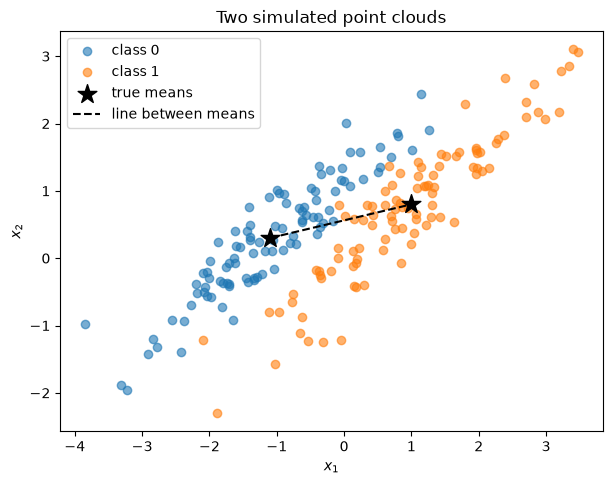

In [2]:
rng = np.random.default_rng(42)
n0 = n1 = 100
mu0 = np.array([-1.1, 0.3])
mu1 = np.array([1.0, 0.8])
Sigma = np.array([[1.2, 1.0], [1.0, 1.0]])

X0 = rng.multivariate_normal(mu0, Sigma, n0)
X1 = rng.multivariate_normal(mu1, Sigma, n1)
X = np.vstack([X0, X1])
y = np.r_[np.zeros(n0, dtype=int), np.ones(n1, dtype=int)]

show_simulated_data(X0, X1, mu0, mu1)

## 2. Mean and variance: just center and spread

- **Mean:** the class center; average each coordinate separately.
- **Variance:** squared spread around that center; larger variance means a wider cloud.
- **Covariance:** whether two coordinates vary together, which creates tilt.

We need only these roles below, not extra arithmetic examples.

In [3]:
# axis=0 calculates one mean or variance per coordinate.
m0 = X0.mean(axis=0)
m1 = X1.mean(axis=0)
v0 = X0.var(axis=0)
v1 = X1.var(axis=0)

print("Class 0 mean and variance:", m0.round(3), v0.round(3))
print("Class 1 mean and variance:", m1.round(3), v1.round(3))

Class 0 mean and variance: [-1.075  0.304] [1.039 0.765]
Class 1 mean and variance: [0.941 0.738] [1.329 1.115]


## 3. Within-class scatter: variance and covariance around each mean

First subtract each class mean. The left plot shows deviation arrows; the right moves both clouds to the origin so their shapes are easy to compare.

For two coordinates, covariance is simply the average product of their deviations:

$$
\operatorname{cov}(x_1,x_2)\approx
\operatorname{average}\bigl[(x_1-m_1)(x_2-m_2)\bigr].
$$

Positive covariance means the coordinates tend to deviate in the same direction.

Within-class **scatter** collects these squared and cross deviations without worrying about a normalization factor:

$$
S_k=\sum_{i:y_i=k}(x_i-m_k)(x_i-m_k)^T,
\qquad S_W=S_0+S_1.
$$

The diagonal contains squared coordinate spreads; the off-diagonal contains covariance-like tilt. Multiplying $S_W$ by a positive constant will not change Fisher's direction.

Within-class scatter S_W:
 [[236.76  195.074]
 [195.074 188.035]]


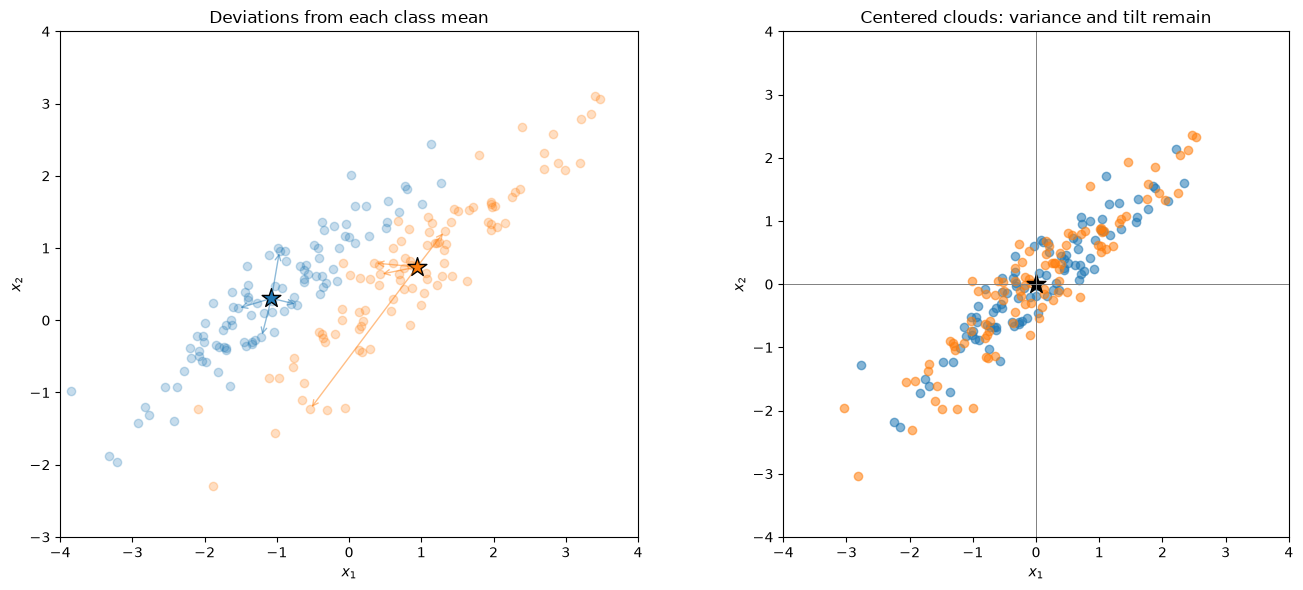

In [4]:
# Center each class, then sum outer products of its deviations.
S0 = (X0 - m0).T @ (X0 - m0)
S1 = (X1 - m1).T @ (X1 - m1)
S_W = S0 + S1

print("Within-class scatter S_W:\n", S_W.round(3))
show_within_class_scatter(X0, X1, m0, m1)

## 4. Projection: keep only the part along a line

Choose a reference $c$ and a unit direction $v$. The arrow from $c$ to a point is $x-c$. Projection keeps its component along $v$:

$$
\boxed{t=v^T(x-c)},\qquad \boxed{p=c+tv}.
$$

The scalar score $t$ tells where the projected point $p$ lies on the line; the perpendicular part is discarded. The reference $c$ is just zero on the score line and does not change spread or class separation.

For example, if $c=(1,1)$, $x=(4,3)$, and $v=(1,0)$, then $x-c=(3,2)$, $t=3$, and $p=(4,1)$. The projected arrow is $p-c=(3,0)$.

The code repeats this construction for one visible point and then for every point in both clouds.

Reference c: [-0.067  0.521]
Example point and projection: [2.5 2.5] [2.5   0.521]


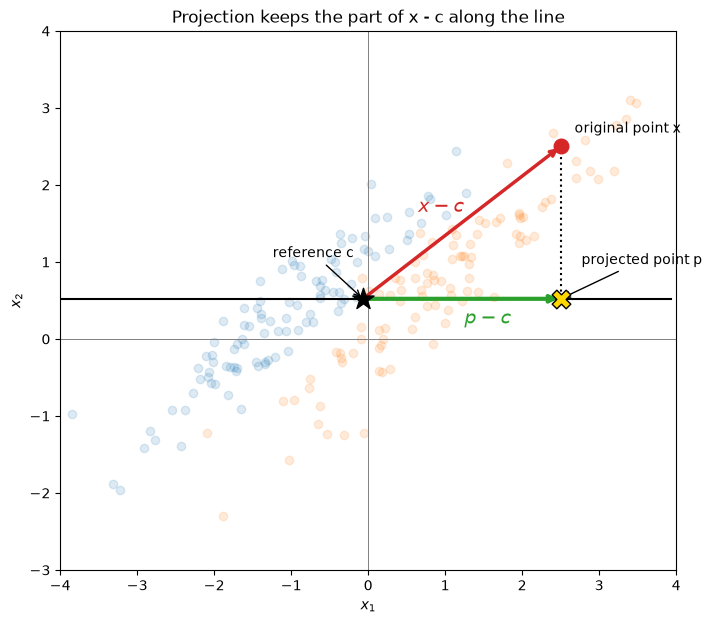

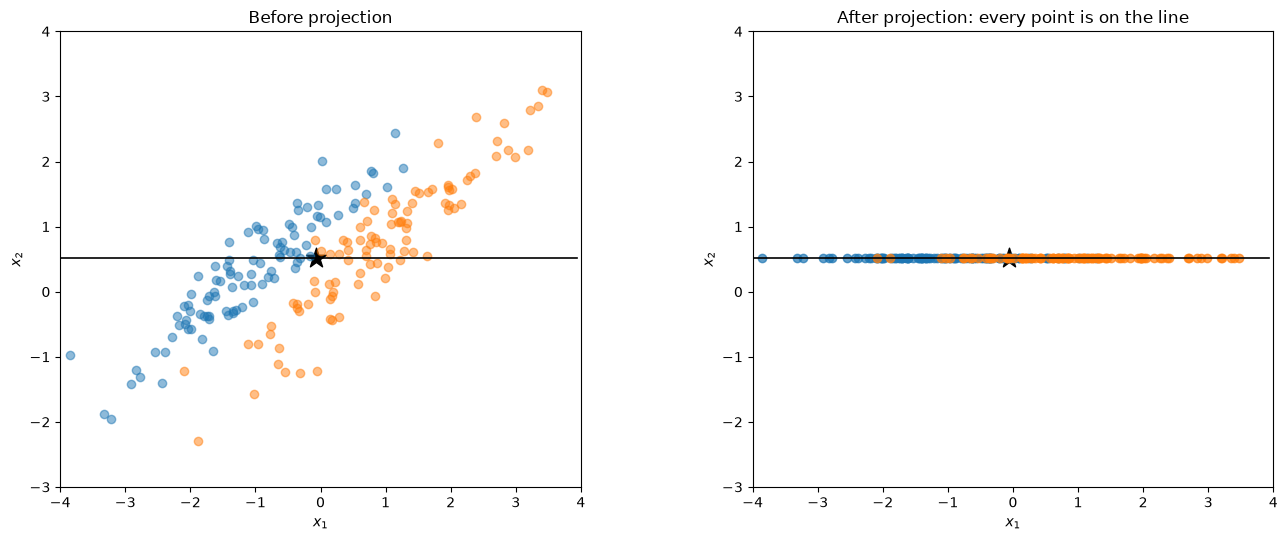

In [5]:
# Use the class-mean midpoint as the reference and project horizontally first.
c = (m0 + m1) / 2
v = np.array([1.0, 0.0])
t0 = (X0 - c) @ v
t1 = (X1 - c) @ v

point = np.array([2.5, 2.5])
projection = c + ((point - c) @ v) * v
P0 = c + t0[:, None] * v
P1 = c + t1[:, None] * v

print("Reference c:", c.round(3))
print("Example point and projection:", point, projection.round(3))
show_projection(X0, X1, c, v, point, projection, P0, P1)

## 5. Projected mean, variance, and $v^TS_Wv$

A projected class mean is simply the mean of its scores:

$$
\bar t_k=v^T(m_k-c).
$$

Projected variance is the spread of scores around $\bar t_k$ along the line.

The matrix expression $v^TS_Wv$ is just total within-class squared deviation. For one class,

$$
v^TS_kv
=\sum_i\bigl(v^T(x_i-m_k)\bigr)^2,
$$

which adds squared distances from projected points to their projected mean. Adding both classes gives

$$
\boxed{v^TS_Wv=v^TS_0v+v^TS_1v=\text{total within-class spread along }v}.
$$

No normalization factor is needed to compare directions. In the plot below, the 2D panel uses centered coordinates $x-c$, so its horizontal positions and the 1D histogram scores use exactly the same scale.

Class 0: direct and v^T S0 v: 103.88763056262232 103.88763056262232
Class 1: direct and v^T S1 v: 132.8719296501497 132.87192965014964
Total: direct and v^T S_W v: 236.75956021277202 236.75956021277196


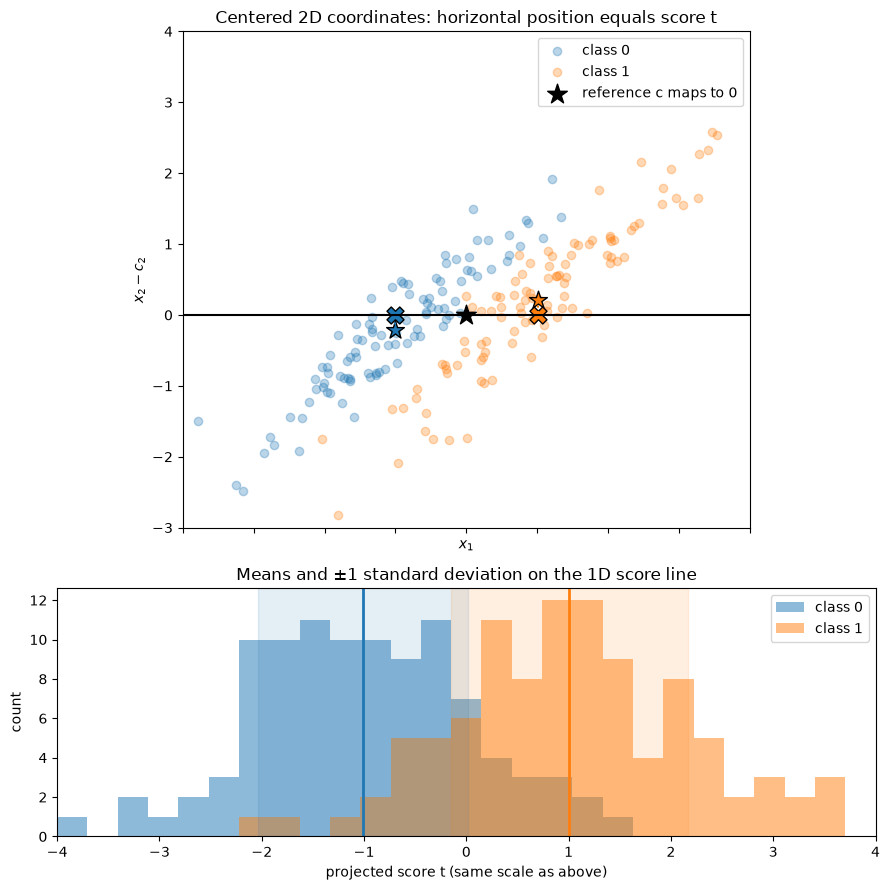

In [6]:
# Direct squared deviations around each projected class mean.
within0 = ((t0 - t0.mean()) ** 2).sum()
within1 = ((t1 - t1.mean()) ** 2).sum()

print("Class 0: direct and v^T S0 v:", within0, v @ S0 @ v)
print("Class 1: direct and v^T S1 v:", within1, v @ S1 @ v)
print("Total: direct and v^T S_W v:", within0 + within1, v @ S_W @ v)
assert np.isclose(within0 + within1, v @ S_W @ v)

show_projected_mean_variance(X0, X1, c, v, t0, t1, m0, m1)

## 6. Fisher's criterion: far-apart centers, narrow clouds

For any direction $v$, compute

$$
\text{between}=(\text{difference of projected means})^2,
\qquad
\text{within}=\text{total within-class squared deviation}.
$$

Fisher's criterion is

$$
\boxed{J(v)=\frac{\text{between}}{\text{within}}
=\frac{v^TS_Bv}{v^TS_Wv}},
\qquad S_B=\delta\delta^T,\quad \delta=m_1-m_0.
$$

A good projection has separated centers and narrow class histograms. Fisher's covariance-adjusted direction is

$$
\boxed{w\propto S_W^{-1}\delta}.
$$

The code compares it with the first-coordinate and mean-difference directions.

First feature: between=4.061, within=236.760, J=0.01715
Mean difference: between=4.250, within=315.003, J=0.01349
Fisher: between=1.275, within=17.669, J=0.07217


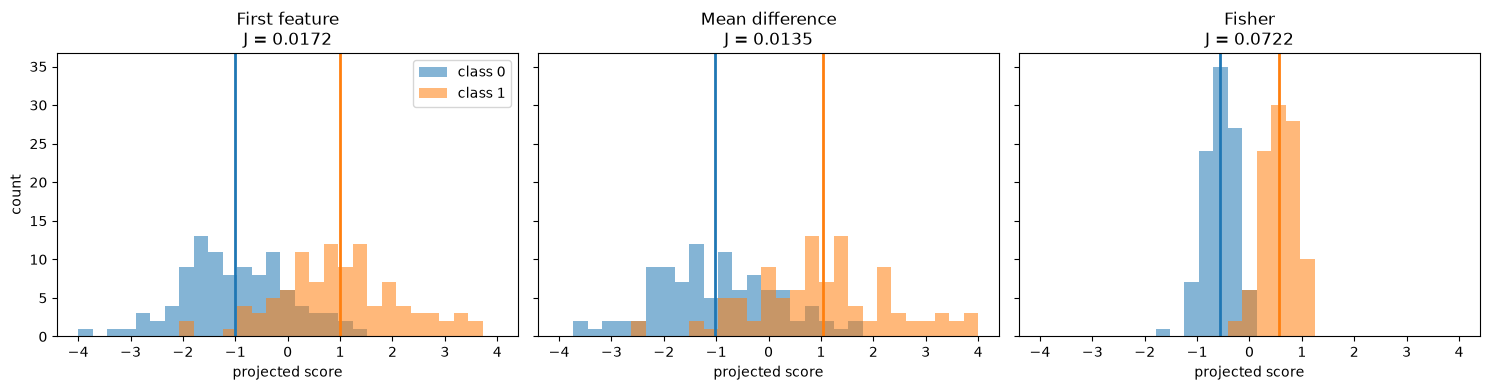

In [7]:
delta = m1 - m0
S_B = np.outer(delta, delta)
w_fisher = np.linalg.solve(S_W, delta)
w = w_fisher / np.linalg.norm(w_fisher)

results = []
for name, direction in {"First feature": v, "Mean difference": delta, "Fisher": w}.items():
    unit_direction = direction / np.linalg.norm(direction)
    scores0 = (X0 - c) @ unit_direction
    scores1 = (X1 - c) @ unit_direction
    between = (scores1.mean() - scores0.mean()) ** 2
    within = ((scores0 - scores0.mean()) ** 2).sum() + ((scores1 - scores1.mean()) ** 2).sum()
    J = between / within
    print(f"{name}: between={between:.3f}, within={within:.3f}, J={J:.5f}")
    results.append((name, scores0, scores1, J))

show_direction_comparison(results)

The mean-difference direction has the largest between value, but also very wide clouds. Fisher wins by making the within spread much smaller; that is the benefit of covariance adjustment.

## 7. Whitening: make the within-class shape round

Tilted clouds have more spread in some directions than others. **Whitening** rotates and rescales the coordinates so that every direction has the same within-class scatter.

The code does this in three steps:

1. `eigh(S_W)` finds the ellipse's axes and the scatter along each axis.
2. Dividing each axis by the square root of its scatter makes the spreads equal.
3. Applying this transformation to every point gives round clouds and whitened scatter $I$.

In matrix form, the transformation is $z=A(x-c)$, and it satisfies

$$
AS_WA^T=I.
$$

After whitening, the mean-difference direction is the natural choice. The final lines map that direction back to the original coordinates and check that it agrees with $S_W^{-1}\delta$. The comments identify what each calculation does.

Within-class scatter after whitening:
 [[ 1. -0.]
 [-0.  1.]]
Cosine with the direct S_W solve: 1.0


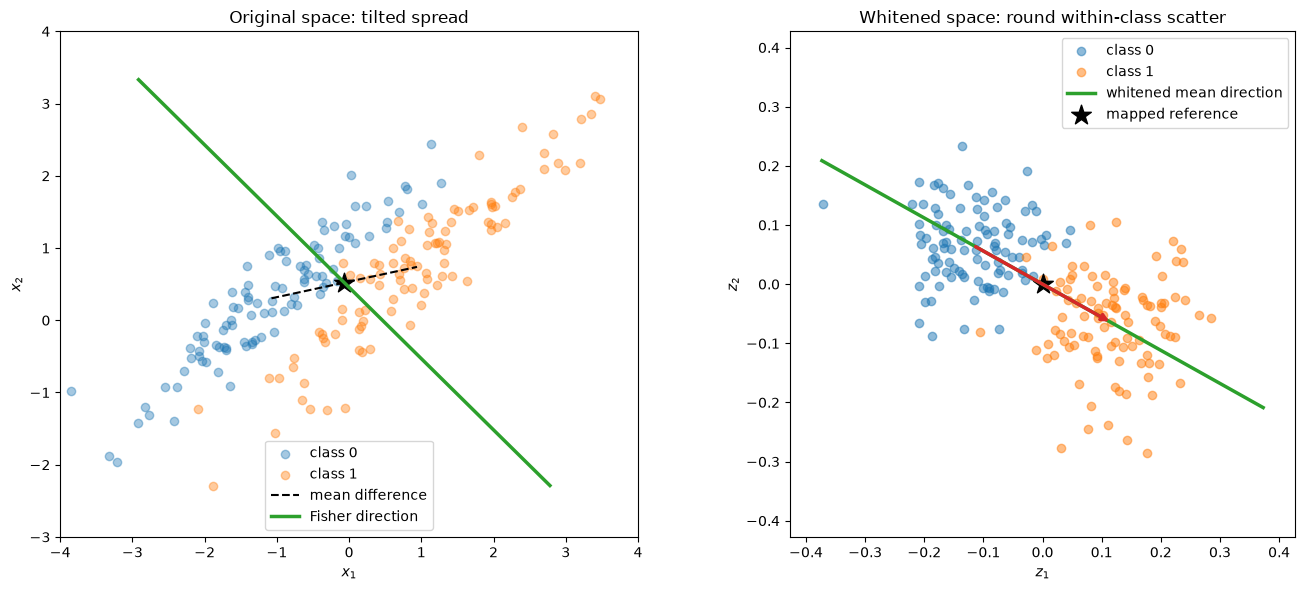

In [8]:
# Step 1: find the axes of the within-class scatter ellipse.
# eigenvectors_W contains the axis directions; eigenvalues_W contains
# the amount of scatter along each axis.
eigenvalues_W, eigenvectors_W = eigh(S_W)

# Step 2: build A = Q diag(1/sqrt(eigenvalues)) Q^T.
# Q^T rotates to the ellipse axes, the division equalizes their spreads,
# and Q rotates back. Dividing the columns of Q applies the middle scaling.
whitening_matrix = (eigenvectors_W / np.sqrt(eigenvalues_W)) @ eigenvectors_W.T

# Step 3: apply z = A(x - c) to every observation.
# Our observations are rows, so we multiply by A.T on the right.
Z0 = (X0 - c) @ whitening_matrix.T
Z1 = (X1 - c) @ whitening_matrix.T

# Recompute within-class scatter in the new coordinates. It should be I.
z_m0, z_m1 = Z0.mean(axis=0), Z1.mean(axis=0)
Z0_centered = Z0 - z_m0
Z1_centered = Z1 - z_m1
white_scatter = Z0_centered.T @ Z0_centered + Z1_centered.T @ Z1_centered
print("Within-class scatter after whitening:\n", white_scatter.round(3))
assert np.allclose(white_scatter, np.eye(2))

# With round scatter, the whitened class-mean difference is the best direction.
delta_z = z_m1 - z_m0
u_z = delta_z / np.linalg.norm(delta_z)

# A is symmetric, so u^T z = (A u)^T (x - c).
# Thus A @ u_z gives the corresponding score direction in original coordinates.
w_from_whitening = whitening_matrix @ u_z
cosine = abs(w_from_whitening @ w) / (np.linalg.norm(w_from_whitening) * np.linalg.norm(w))
print("Cosine with the direct S_W solve:", cosine)
assert np.isclose(cosine, 1.0)

show_whitening(X0, X1, Z0, Z1, m0, m1, c, w, z_m0, z_m1, u_z)

## 8. A direction becomes a classifier after adding a threshold

Fisher's solution chooses the projection line; classification also needs a threshold. For equal class priors and shared covariance, the midpoint $c$ gives

$$
\widehat y=\begin{cases}
1,&w^T(x-c)>0,\\
0,&\text{otherwise}.
\end{cases}
$$

The decision boundary $w^T(x-c)=0$ is perpendicular to the projection direction. We generate fresh test points below rather than evaluating only on the data used to estimate $w$.

The black line in the plot is the separation boundary; the green arrow is the projection direction used to decide which side a point is on.

Manual LDA test accuracy: 0.98


scikit-learn LDA test accuracy: 0.98
Same predictions: True


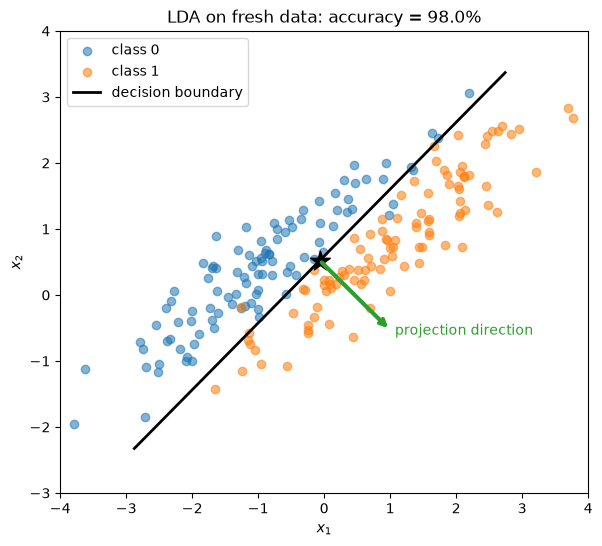

In [9]:
X0_test = rng.multivariate_normal(mu0, Sigma, n0)
X1_test = rng.multivariate_normal(mu1, Sigma, n1)
X_test = np.vstack([X0_test, X1_test])
y_test = np.r_[np.zeros(n0, dtype=int), np.ones(n1, dtype=int)]

# Positive scores are class 1; negative scores are class 0.
y_predicted = ((X_test - c) @ w > 0).astype(int)
manual_accuracy = np.mean(y_predicted == y_test)
print("Manual LDA test accuracy:", manual_accuracy)

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis().fit(X, y)
print("scikit-learn LDA test accuracy:", lda.score(X_test, y_test))
print("Same predictions:", np.array_equal(y_predicted, lda.predict(X_test)))

show_decision_boundary(X0_test, X1_test, c, w, manual_accuracy)

## 9. Optimization in one short derivation

Fisher's ratio does not change when $w$ is stretched: $J(aw)=J(w)$. Therefore we can fix the within-class spread and maximize only the separation:

$$
\max_w w^TS_Bw\quad\text{subject to}\quad w^TS_Ww=1.
$$

The constraint is an ellipse in original coordinates and a circle after whitening.

A **Lagrangian** handles such a constraint. For maximize $x+y$ on $x^2+y^2=1$, the largest allowed objective occurs where a level line is tangent to the circle:

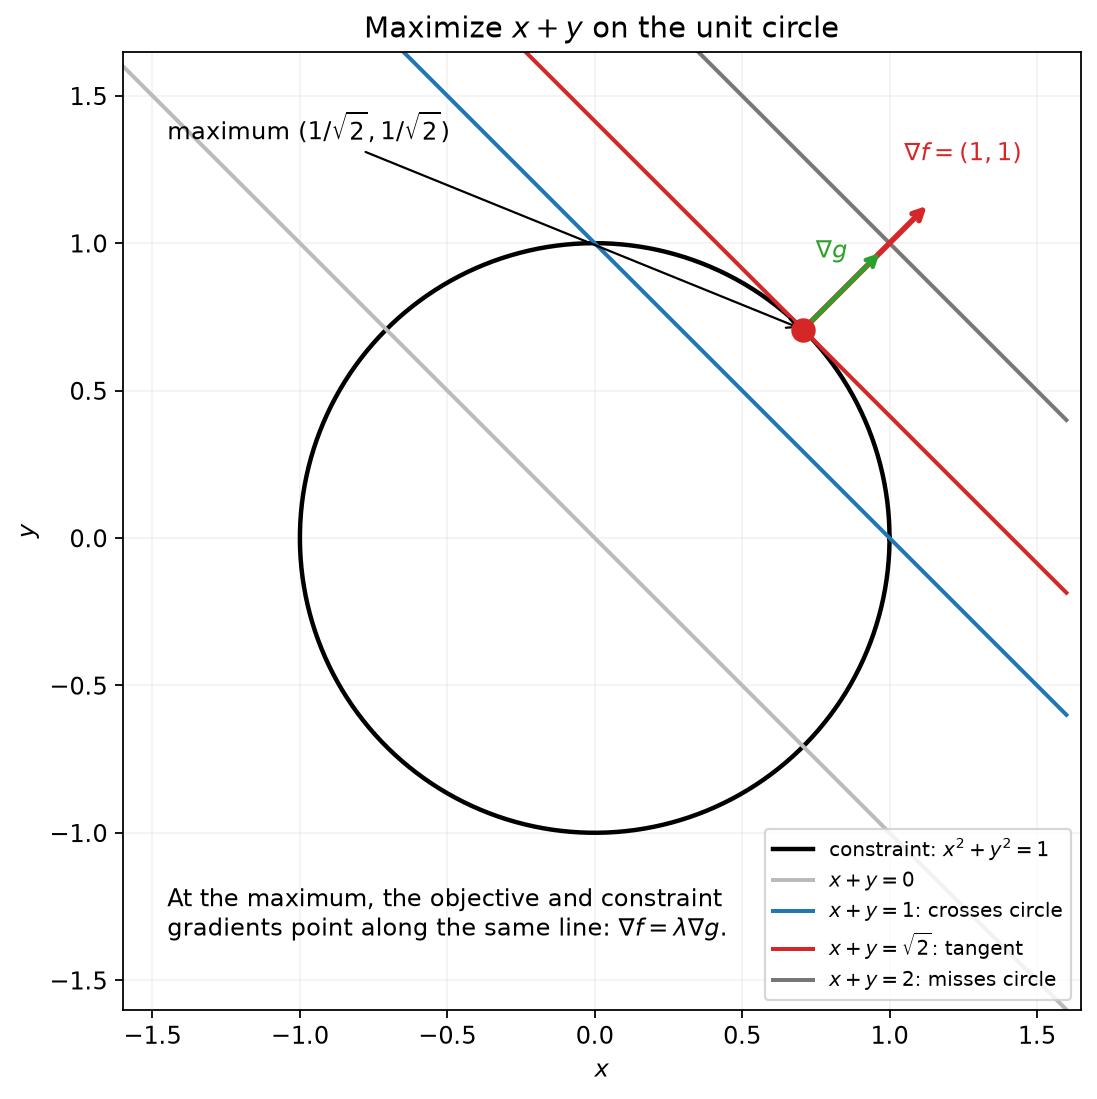

At tangency, the objective and constraint gradients are parallel. Writing $f$ for the objective and $g=0$ for the constraint, the Lagrangian is $\mathcal L=f-\lambda g$, and its stationary condition is

$$
\nabla f=\lambda\nabla g.
$$

For Fisher's problem,

$$
\mathcal L(w,\lambda)=w^TS_Bw-\lambda(w^TS_Ww-1).
$$

Because $S_B$ and $S_W$ are symmetric, setting the gradient to zero gives

$$
2S_Bw=2\lambda S_Ww
\quad\Longrightarrow\quad
\boxed{S_Bw=\lambda S_Ww}.
$$

This is a generalized eigenvalue problem. Multiplying by $w^T$ and using $w^TS_Ww=1$ gives $\lambda=w^TS_Bw$, so the largest eigenvalue corresponds to the best Fisher score.

## 10. Two classes: the eigenvalue problem leaves one arrow

After whitening, $S_B^{(z)}=\delta_z\delta_z^T$. For any candidate $u$,

$$
S_B^{(z)}u=\delta_z(\delta_z^Tu).
$$

The output always points along $\delta_z$; only its length changes. This is what **rank one** means.

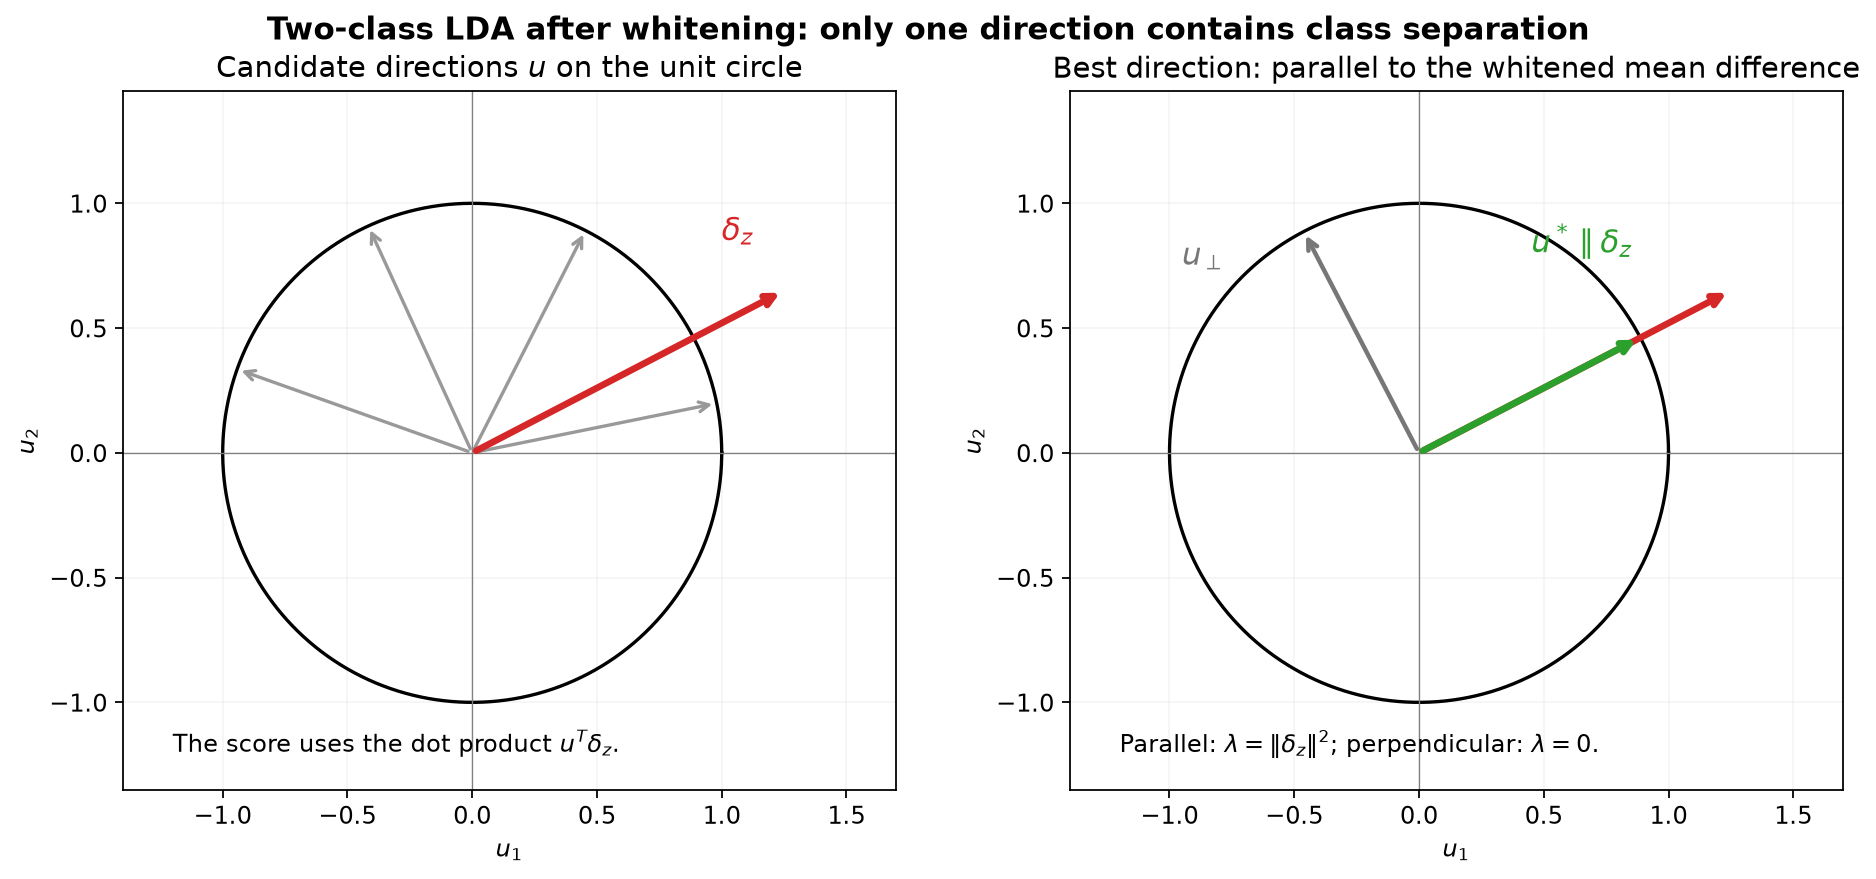

Thus the direction parallel to $\delta_z$ has the only nonzero eigenvalue, $\lambda=\|\delta_z\|^2$. A perpendicular direction has eigenvalue zero. The best unit direction is simply $u^*=\delta_z/\|\delta_z\|$.

The original generalized equation gives the same result without whitening. Since $S_B=\delta\delta^T$,

$$
\delta(\delta^Tw)=\lambda S_Ww
\quad\Longrightarrow\quad
w=\frac{\delta^Tw}{\lambda}S_W^{-1}\delta
\quad\Longrightarrow\quad
\boxed{w\propto S_W^{-1}\delta}.
$$

The scalar factor does not change the direction. **For two classes, solving $S_Ww=\delta$ is enough.** The next cell only checks this agreement numerically.

In [10]:
# Numerical check: the leading eigenvector and direct solution agree.
eigenvalues, eigenvectors = eigh(S_B, S_W)
w_eigen = eigenvectors[:, -1]
cosine = abs(w_eigen @ w) / (np.linalg.norm(w_eigen) * np.linalg.norm(w))
print("Generalized eigenvalues:", eigenvalues)
print("Cosine with S_W inverse direction:", cosine)
assert np.isclose(cosine, 1.0)

Generalized eigenvalues: [-6.27152656e-19  7.21679120e-02]
Cosine with S_W inverse direction: 1.0000000000000002


## 11. Multiple classes: one direction becomes a discriminant subspace

Two classes need one discriminant direction. For $K$ classes, we can have up to $\min(d,K-1)$ directions, where $d$ is the number of original features.

The within-class matrix is still the sum of deviations around class means. Between-class scatter now combines every class mean's deviation from the overall mean $m$:

$$
S_W=\sum_k\sum_{y_i=k}(x_i-m_k)(x_i-m_k)^T,
\qquad
S_B=\sum_k n_k(m_k-m)(m_k-m)^T.
$$

We solve the same generalized eigenvalue problem, $S_Bv=\lambda S_Wv$, but keep eigenvectors with the largest eigenvalues. Each gives one discriminant score.

There are at most $K-1$ useful directions because $K$ class means have at most $K-1$ independent deviations from their common mean.

The Iris dataset has four features and three classes, so LDA can produce two scores. The left plot uses two original features; the right uses the two learned discriminant directions. Percentages describe fractions of generalized-eigenvalue separation, not ordinary explained variance.

Maximum useful LDA dimensions: 2
Generalized eigenvalues: [ 3.21919292e+01  2.85391043e-01  5.23228317e-15 -4.30300631e-16]
Separation captured by LD1 and LD2: [0.9912 0.0088]


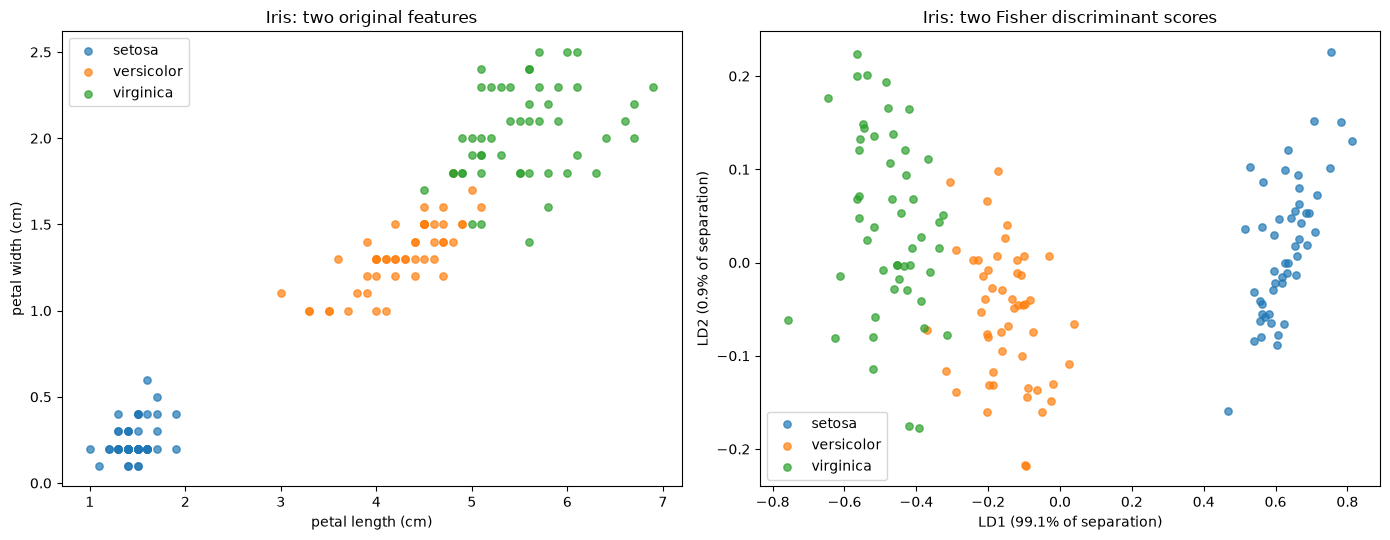

In [11]:
# Iris is bundled with scikit-learn; no download is needed.
from sklearn.datasets import load_iris
iris = load_iris()
X_iris, y_iris = iris.data, iris.target
K_iris = len(np.unique(y_iris))
mean_iris = X_iris.mean(axis=0)
class_means_iris = np.array([X_iris[y_iris == k].mean(axis=0) for k in range(K_iris)])

# Within-class deviations around each class mean.
S_W_iris = sum(
    (X_iris[y_iris == k] - class_means_iris[k]).T @ (X_iris[y_iris == k] - class_means_iris[k])
    for k in range(K_iris)
)
# Between-class deviations from the overall mean, weighted by class size.
S_B_iris = sum(
    np.sum(y_iris == k) * np.outer(class_means_iris[k] - mean_iris, class_means_iris[k] - mean_iris)
    for k in range(K_iris)
)

# Keep the two directions with the largest generalized eigenvalues.
evals_iris, evecs_iris = eigh(S_B_iris, S_W_iris)
order = np.argsort(evals_iris)[::-1]
evals_iris, evecs_iris = evals_iris[order], evecs_iris[:, order]
V_iris = evecs_iris[:, :2]
Z_iris = (X_iris - mean_iris) @ V_iris
separation_ratio = np.clip(evals_iris, 0, None)
separation_ratio = separation_ratio / separation_ratio.sum()

print("Maximum useful LDA dimensions:", min(X_iris.shape[1], K_iris - 1))
print("Generalized eigenvalues:", evals_iris)
print("Separation captured by LD1 and LD2:", separation_ratio[:2].round(4))
assert Z_iris.shape == (len(X_iris), 2)
show_iris_lda(X_iris, y_iris, Z_iris, separation_ratio, iris.target_names)

## 12. The core ideas

1. **Mean and variance:** center and spread; covariance also describes tilt.
2. **Projection:** keep the part of $x-c$ along a line.
3. **Within-class scatter:** $v^TS_Wv$ is total squared spread after projection.
4. **Fisher's criterion:** maximize between-class separation divided by within-class spread.
5. **Whitening:** round clouds make the mean difference optimal; mapping back gives $w\propto S_W^{-1}\delta$.
6. **Classification:** use the projection direction together with a threshold and decision boundary.
7. **Optimization:** the Lagrangian gives $S_Bw=\lambda S_Ww$, but two classes need only one useful direction.

The Iris example shows how generalized eigenvectors provide up to $K-1$ discriminant directions for $K$ classes. If $S_W$ is singular, regularization or a pseudoinverse is needed instead of the simple inverse formula.